# Eje C: resultados de FQI para elegir el ajuste del MPC

Visualización del modelo que deja `fqi_ajuste.py` en `fqi_s0.pkl`. La política mira el estado cada $M$ pasos de control y elige uno de los $K$ ajustes $(Q_\text{mpc}, R_\text{mpc}, N)$; el valor de cada ajuste es $Q(s, a)$, aproximado con Extra-Trees por Fitted Q Iteration.

1. Resumen de la corrida y convergencia de FQI.
2. Qué aprendió: mapa de la política, $V(s) = \max_a Q(s,a)$ y cuánto importa la elección.
3. Lazo cerrado: política FQI contra cada ajuste fijo, en una grilla $(\theta_0, \dot x_0)$ y en estados al azar de la caja de entrenamiento.
4. Una trayectoria de ejemplo con los cambios de ajuste.

Todas las evaluaciones miden el costo con la métrica **fija** del env ($p.Q$, $p.R$), no con los pesos de cada ajuste.

In [1]:
import sys, pickle, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm

RAIZ = Path.cwd().parent if Path.cwd().name == "inciso_C" else Path.cwd()
sys.path[:0] = [str(RAIZ / "simulador"), str(RAIZ / "inciso_C")]

import fqi_ajuste as fq
from pendulo_env import PenduloEnv, ParametrosPlanta

with open(RAIZ / "inciso_C" / "fqi_s0.pkl", "rb") as f:
    res = pickle.load(f)

modelo, cfg, AJUSTES, historial = res["modelo"], res["cfg"], res["ajustes"], res["historial"]
K, M = len(AJUSTES), cfg["M"]
NOMBRES = [a["nombre"] for a in AJUSTES]
COLORES = ["#4C72B0", "#DD8452", "#55A868", "#C44E52"][:K]
CMAP_AJ = ListedColormap(COLORES)
NORM_AJ = BoundaryNorm(np.arange(-0.5, K), K)

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

c:\Users\agusm\Desktop\Vision_por_computadora\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator ExtraTreeRegressor from version 1.7.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
c:\Users\agusm\Desktop\Vision_por_computadora\.venv\Lib\site-packages\sklearn\base.py:525: InconsistentVersionWarning: Trying to unpickle estimator ExtraTreesRegressor from version 1.7.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 1. Resumen de la corrida

In [2]:
print(f"transiciones simuladas: {res['pasos_simulados']} pasos de control "
      f"({res['t_datos_s'] / 60:.1f} min de recolección)")
print(f"c_barra (percentil {cfg['percentil_c_barra']:.0f} del costo sin falla): {res['c_barra']:.1f}")
print(f"gamma = {cfg['gamma']}, M = {M} pasos ({M * 20} ms por decisión), "
      f"{cfg['iteraciones']} iteraciones, bosque congelado desde la {cfg['congelar_desde']}")
print(f"caja de estados iniciales: ±{cfg['caja']}  (x, x_d, theta, theta_d)\n")
pd.DataFrame(AJUSTES).set_index("nombre")

transiciones simuladas: 92173 pasos de control (7.3 min de recolección)
c_barra (percentil 99 del costo sin falla): 7374.0
gamma = 0.95, M = 10 pasos (200 ms por decisión), 60 iteraciones, bosque congelado desde la 20
caja de estados iniciales: ±[0.45 2.   0.8  4.  ]  (x, x_d, theta, theta_d)



,Q,R,N
nombre,,,
base,"[10.0, 1.0, 100.0, 1.0]",0.1,10
agresivo,"[10.0, 1.0, 400.0, 4.0]",0.1,10
conservador,"[10.0, 1.0, 100.0, 1.0]",1.0,10
horizonte,"[10.0, 1.0, 100.0, 1.0]",0.1,20


### Convergencia

$\max_i |y^{(k+1)}_i - y^{(k)}_i|$ por iteración. Mientras el bosque se reconstruye en cada iteración (zona gris) no hay garantía de contracción; con la estructura congelada el operador es una contracción de módulo $\gamma$ y el cambio debería caer como $\gamma^k$ (línea punteada).

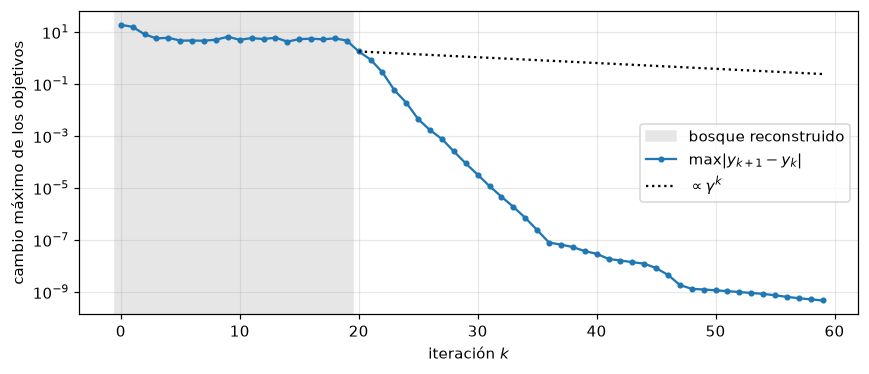

In [3]:
it = np.array([h["iteracion"] for h in historial])
cambio = np.array([h["cambio_max_objetivos"] for h in historial])
k0 = cfg["congelar_desde"]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.axvspan(-0.5, k0 - 0.5, color="0.9", label="bosque reconstruido")
ax.semilogy(it, cambio, "o-", ms=3, label=r"$\max|y_{k+1}-y_k|$")
ref = cambio[k0] * cfg["gamma"] ** (it[k0:] - k0)
ax.semilogy(it[k0:], ref, "k:", label=r"$\propto\gamma^k$")
ax.set_xlabel("iteración $k$"); ax.set_ylabel("cambio máximo de los objetivos")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Qué aprendió la política

`Q_tabla` evalúa $Q(s, a)$ para muchos estados y los $K$ ajustes a la vez. Los cortes se hacen en el plano $(\theta_0, \dot x_0)$ con $x = \dot\theta = 0$ (el mismo del eje A), y en $(\theta_0, \dot\theta_0)$ con $x = \dot x = 0$.

In [4]:
def Q_tabla(estados):
    estados = np.atleast_2d(estados)
    n = len(estados)
    X = fq.entrada(np.repeat(estados, K, axis=0), np.tile(np.arange(K), n), K)
    return modelo.predict(X).reshape(n, K)

def corte(eje1, val1, eje2, val2):
    # estados en una grilla sobre los ejes eje1, eje2 (índices en x, x_d, theta, theta_d)
    G1, G2 = np.meshgrid(val1, val2)
    S = np.zeros((G1.size, 4))
    S[:, eje1], S[:, eje2] = G1.ravel(), G2.ravel()
    return Q_tabla(S).reshape(*G1.shape, K)

ETIQ = ["$x_0$ [m]", r"$\dot x_0$ [m/s]", r"$\theta_0$ [rad]", r"$\dot\theta_0$ [rad/s]"]
caja = cfg["caja"]
thetas = np.linspace(-caja[2], caja[2], 121)
cortes = {
    "xd": (2, thetas, 1, np.linspace(-caja[1], caja[1], 121)),
    "thd": (2, thetas, 3, np.linspace(-caja[3], caja[3], 121)),
}
Qs = {k: corte(*v) for k, v in cortes.items()}

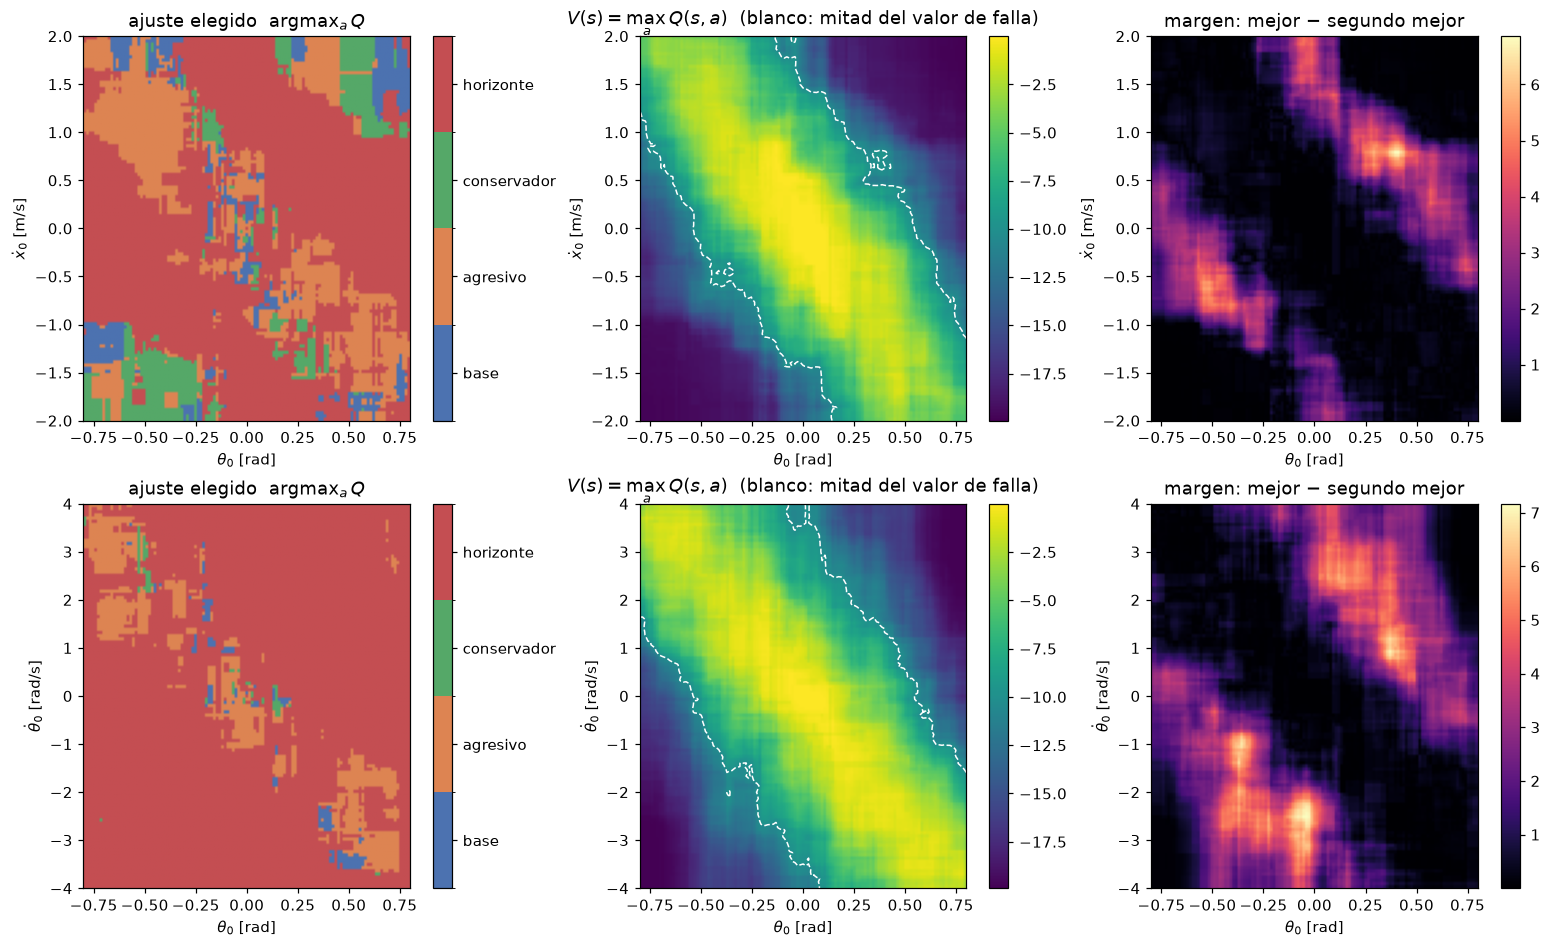

In [5]:
fig, axs = plt.subplots(2, 3, figsize=(14, 8.5), constrained_layout=True)
for fila, (clave, (e1, v1, e2, v2)) in zip(axs, cortes.items()):
    Q = Qs[clave]
    ext = [v1[0], v1[-1], v2[0], v2[-1]]
    Qord = np.sort(Q, axis=-1)

    im = fila[0].imshow(Q.argmax(-1), origin="lower", extent=ext, aspect="auto", cmap=CMAP_AJ, norm=NORM_AJ)
    fila[0].set_title("ajuste elegido  argmax$_a\\,Q$")
    cb = fig.colorbar(im, ax=fila[0], ticks=range(K)); cb.ax.set_yticklabels(NOMBRES)

    im = fila[1].imshow(Qord[..., -1], origin="lower", extent=ext, aspect="auto", cmap="viridis")
    fila[1].contour(v1, v2, Qord[..., -1], levels=[-0.5 / (1 - cfg["gamma"])], colors="w", linewidths=1)
    fila[1].set_title(r"$V(s)=\max_a Q(s,a)$  (blanco: mitad del valor de falla)")
    fig.colorbar(im, ax=fila[1])

    im = fila[2].imshow(Qord[..., -1] - Qord[..., -2], origin="lower", extent=ext, aspect="auto", cmap="magma")
    fila[2].set_title("margen: mejor $-$ segundo mejor")
    fig.colorbar(im, ax=fila[2])

    for ax in fila:
        ax.set_xlabel(ETIQ[e1]); ax.set_ylabel(ETIQ[e2]); ax.grid(False)
plt.show()

El valor de falla es $-1/(1-\gamma) = -20$ y un intervalo sin falla vale entre $-1$ y $0$, así que $V$ separa con claridad la región recuperable de la que no. El **margen** dice dónde la elección del ajuste realmente cambia algo: donde es casi cero, cualquier ajuste da lo mismo según $Q$ y el color del mapa de la izquierda es ruido del regresor.

### Cuánto se elige cada ajuste

Proporción de estados, muestreados uniforme en la caja de entrenamiento, en que cada ajuste es el argmax, separando estados recuperables ($V > -10$) de los que no.

In [6]:
rng = np.random.default_rng(123)
S_azar = rng.uniform(-caja, caja, size=(20000, 4))
Q_azar = Q_tabla(S_azar)
V_azar, a_azar = Q_azar.max(1), Q_azar.argmax(1)
recup = V_azar > -0.5 / (1 - cfg["gamma"])

tabla = pd.DataFrame({
    "recuperables": np.bincount(a_azar[recup], minlength=K) / recup.sum(),
    "no recuperables": np.bincount(a_azar[~recup], minlength=K) / (~recup).sum(),
}, index=NOMBRES)
print(f"fracción de la caja con V > -10: {recup.mean():.2%}")
tabla.style.format("{:.1%}")

fracción de la caja con V > -10: 50.17%


,recuperables,no recuperables
base,5.7%,24.0%
agresivo,26.6%,9.3%
conservador,3.0%,7.2%
horizonte,64.7%,59.5%


## 3. Lazo cerrado: FQI contra los ajustes fijos

`simular` corre 5 s (250 pasos de 20 ms) con una política que se consulta cada $M$ pasos; un ajuste fijo es la política constante. Al cambiar de ajuste se reinicia el warm start del MPC nuevo, igual que en `fq.lazo_cerrado`. El resultado es:

- **estabiliza**: no se cae ni sale del riel y termina con $|\theta| < 0.05$ y $|x| < 0.1$,
- **no estabiliza**: aguanta los 5 s pero no llega a esa zona,
- **cae** / **sale del riel**: el episodio termina antes.

In [7]:
p = ParametrosPlanta()
env = PenduloEnv(p)
mpcs = fq.crear_mpcs(p)

def simular(politica, estado0, pasos=250, guardar=False):
    x, _ = env.reset(options={"estado": estado0})
    costo, cambios, a_previa = 0.0, 0, None
    tray = {"x": [x], "F": [], "a": []}
    resultado = None
    for t in range(pasos):
        if t % M == 0:
            a = politica(x)
            if a != a_previa:
                mpcs[a].reiniciar()
                cambios += a_previa is not None
            a_previa = a
        F = mpcs[a].solve(x)
        x, _, terminado, _, info = env.step([F])
        costo += info["costo"]
        if guardar:
            tray["x"].append(x); tray["F"].append(F); tray["a"].append(a)
        if terminado:
            resultado = "sale del riel" if info["fuera_riel"] else "cae"
            break
    if resultado is None:
        resultado = "estabiliza" if abs(x[2]) < 0.05 and abs(x[0]) < 0.1 else "no estabiliza"
    salida = {"resultado": resultado, "costo": costo, "cambios": cambios, "pasos": t + 1}
    if guardar:
        salida["tray"] = {k: np.array(v) for k, v in tray.items()}
    return salida

POLITICAS = {"FQI": lambda s: fq.elegir_ajuste(modelo, s, K)}
POLITICAS.update({n: (lambda s, i=i: i) for i, n in enumerate(NOMBRES)})

### Región de recuperación en el plano $(\theta_0, \dot x_0)$

Para cada estado inicial de la grilla, el resultado con cada política. Si FQI aprendió algo útil, su región verde debería contener la unión de las regiones de los ajustes fijos, o acercarse.

In [8]:
g_th = np.linspace(-0.75, 0.75, 13)
g_xd = np.linspace(-2.0, 2.0, 13)
filas = []
t0 = time.perf_counter()
for nombre, pol in POLITICAS.items():
    for xd in g_xd:
        for th in g_th:
            r = simular(pol, [0.0, xd, th, 0.0])
            filas.append({"politica": nombre, "theta0": th, "xd0": xd, **r})
grilla = pd.DataFrame(filas)
print(f"{len(grilla)} simulaciones en {time.perf_counter() - t0:.0f} s")

845 simulaciones en 468 s


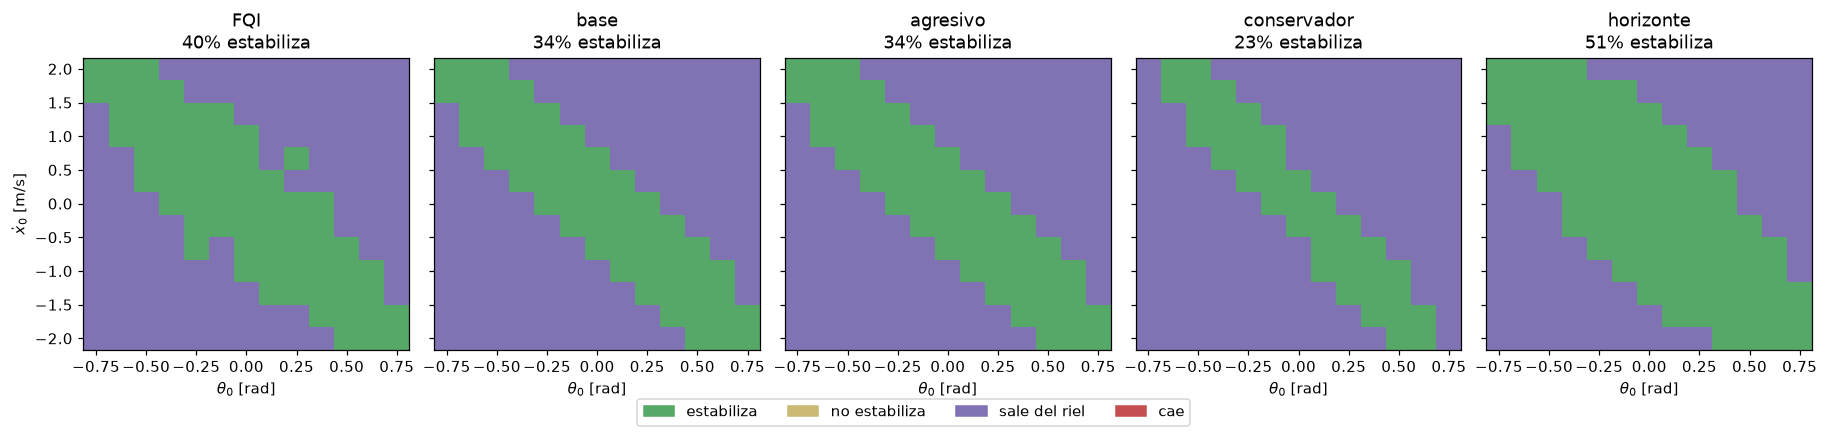

In [9]:
RESULTADOS = ["estabiliza", "no estabiliza", "sale del riel", "cae"]
COL_RES = ListedColormap(["#55A868", "#CCB974", "#8172B3", "#C44E52"])

fig, axs = plt.subplots(1, len(POLITICAS), figsize=(3.3 * len(POLITICAS), 3.6), sharey=True, constrained_layout=True)
for ax, nombre in zip(axs, POLITICAS):
    d = grilla[grilla.politica == nombre]
    Z = d.resultado.map(RESULTADOS.index).to_numpy().reshape(len(g_xd), len(g_th))
    dth, dxd = g_th[1] - g_th[0], g_xd[1] - g_xd[0]
    ax.imshow(Z, origin="lower", cmap=COL_RES, vmin=-0.5, vmax=3.5, aspect="auto",
              extent=[g_th[0] - dth / 2, g_th[-1] + dth / 2, g_xd[0] - dxd / 2, g_xd[-1] + dxd / 2])
    ax.set_title(f"{nombre}\n{(d.resultado == 'estabiliza').mean():.0%} estabiliza")
    ax.set_xlabel(ETIQ[2]); ax.grid(False)
axs[0].set_ylabel(ETIQ[1])
fig.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COL_RES.colors], labels=RESULTADOS,
           loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.08))
plt.show()

### Estados al azar de la caja de entrenamiento

Los mismos 150 estados iniciales para todas las políticas. El costo medio se compara solo sobre los estados que **todas** las políticas estabilizan, porque un episodio que se cae antes acumula menos pasos y su costo no es comparable.

In [10]:
rng = np.random.default_rng(7)
iniciales = rng.uniform(-caja, caja, size=(150, 4))
filas = []
t0 = time.perf_counter()
for nombre, pol in POLITICAS.items():
    for i, s0 in enumerate(iniciales):
        filas.append({"politica": nombre, "estado": i, **simular(pol, s0)})
azar = pd.DataFrame(filas)
print(f"{len(azar)} simulaciones en {time.perf_counter() - t0:.0f} s")

ok_todas = azar.assign(ok=azar.resultado == "estabiliza").groupby("estado").ok.all()
comunes = ok_todas[ok_todas].index
print(f"estados que estabilizan todas las políticas: {len(comunes)} de {len(iniciales)}")

resumen = azar.groupby("politica", sort=False).agg(
    estabiliza=("resultado", lambda r: (r == "estabiliza").mean()),
    no_estabiliza=("resultado", lambda r: (r == "no estabiliza").mean()),
    sale_del_riel=("resultado", lambda r: (r == "sale del riel").mean()),
    cae=("resultado", lambda r: (r == "cae").mean()),
    cambios_medios=("cambios", "mean"),
)
resumen["costo medio (comunes)"] = azar[azar.estado.isin(comunes)].groupby("politica", sort=False).costo.mean()
resumen.style.format({c: "{:.1%}" for c in ["estabiliza", "no_estabiliza", "sale_del_riel", "cae"]}
                     | {"cambios_medios": "{:.2f}", "costo medio (comunes)": "{:.0f}"})

750 simulaciones en 365 s
estados que estabilizan todas las políticas: 32 de 150


,estabiliza,no_estabiliza,sale_del_riel,cae,cambios_medios,costo medio (comunes)
politica,,,,,,
FQI,44.0%,0.0%,54.0%,2.0%,7.15,431
base,37.3%,0.0%,60.7%,2.0%,0.00,424
agresivo,38.7%,0.0%,59.3%,2.0%,0.00,436
conservador,21.3%,0.0%,76.7%,2.0%,0.00,461
horizonte,48.7%,0.0%,49.3%,2.0%,0.00,424


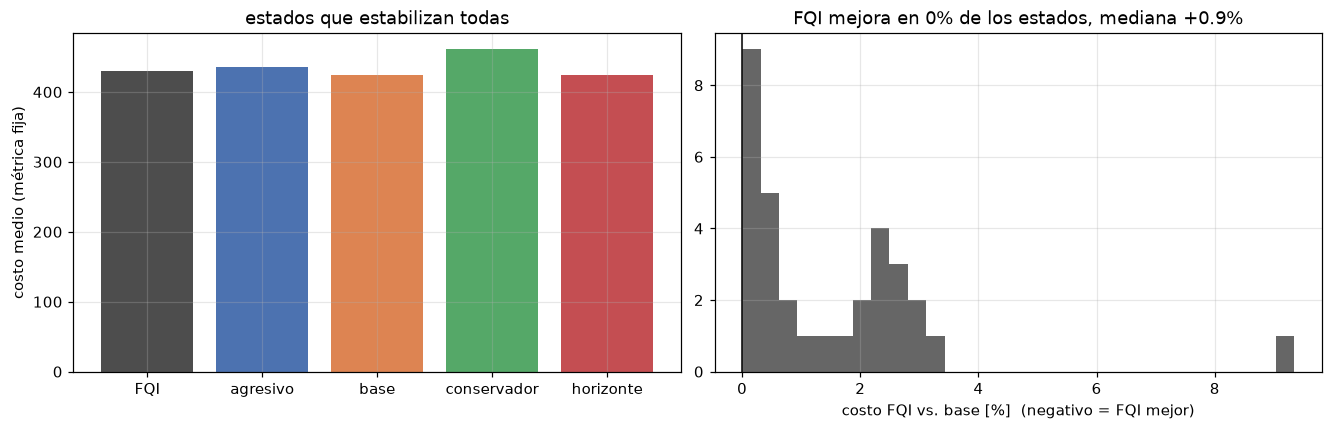

costo medio: FQI 431, mejor fijo (base) 424, oráculo por estado 424


In [11]:
d = azar.pivot(index="estado", columns="politica", values="costo").loc[comunes]
fijos = NOMBRES
mejor_fijo = d[fijos].mean().idxmin()
rel = d["FQI"] / d[mejor_fijo] - 1

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8), constrained_layout=True)
axs[0].bar(d.columns, d.mean(), color=["0.3"] + COLORES)
axs[0].set_ylabel("costo medio (métrica fija)"); axs[0].set_title("estados que estabilizan todas")
axs[1].hist(100 * rel, bins=30, color="0.4")
axs[1].axvline(0, color="k", lw=1)
axs[1].set_xlabel(f"costo FQI vs. {mejor_fijo} [%]  (negativo = FQI mejor)")
axs[1].set_title(f"FQI mejora en {(rel < 0).mean():.0%} de los estados, mediana {100 * rel.median():+.1f}%")
plt.show()

# Contra el mejor fijo POR ESTADO (un oráculo que conoce el futuro)
oraculo = d[fijos].min(axis=1)
print(f"costo medio: FQI {d['FQI'].mean():.0f}, mejor fijo ({mejor_fijo}) {d[mejor_fijo].mean():.0f}, "
      f"oráculo por estado {oraculo.mean():.0f}")

## 4. Una trayectoria de ejemplo

El estado inicial en que FQI más cambia de ajuste entre los que estabiliza. Arriba, el ajuste activo en cada intervalo de $M$ pasos.

estado inicial: [ 0.241 -0.168 -0.203  0.367]
  FQI          estabiliza     costo      157  cambios 21
  base         estabiliza     costo      153  cambios 0


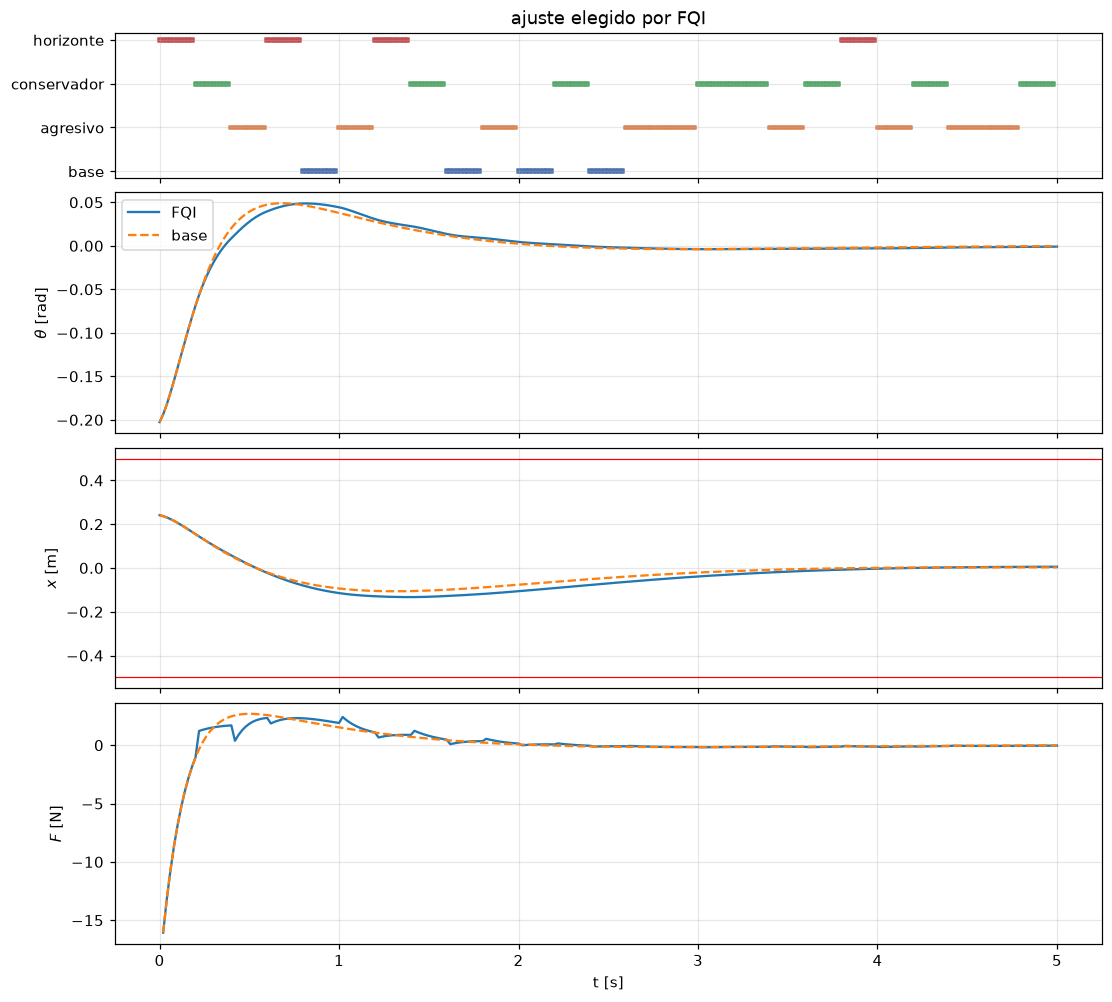

In [12]:
cand = azar[(azar.politica == "FQI") & (azar.resultado == "estabiliza")].sort_values("cambios", ascending=False)
i0 = int(cand.iloc[0].estado) if len(cand) else 0
s0 = iniciales[i0]
print("estado inicial:", np.round(s0, 3))

trays = {n: simular(POLITICAS[n], s0, guardar=True) for n in ["FQI", mejor_fijo]}
for n, r in trays.items():
    print(f"  {n:12s} {r['resultado']:14s} costo {r['costo']:8.0f}  cambios {r['cambios']}")

fig, axs = plt.subplots(4, 1, figsize=(10, 9), sharex=True, constrained_layout=True,
                        gridspec_kw={"height_ratios": [0.6, 1, 1, 1]})
tr = trays["FQI"]["tray"]
t = np.arange(len(tr["a"])) * p.dt
axs[0].scatter(t, tr["a"], c=[COLORES[a] for a in tr["a"]], s=6, marker="s")
axs[0].set_yticks(range(K)); axs[0].set_yticklabels(NOMBRES); axs[0].set_title("ajuste elegido por FQI")
for n, estilo in zip(trays, ["-", "--"]):
    tr = trays[n]["tray"]
    tx = np.arange(len(tr["x"])) * p.dt
    axs[1].plot(tx, tr["x"][:, 2], estilo, label=n)
    axs[2].plot(tx, tr["x"][:, 0], estilo, label=n)
    axs[3].plot(tx[1:], tr["F"], estilo, label=n)
axs[1].set_ylabel(r"$\theta$ [rad]"); axs[2].set_ylabel("$x$ [m]"); axs[3].set_ylabel("$F$ [N]")
axs[2].axhline(p.x_max, color="r", lw=0.8); axs[2].axhline(-p.x_max, color="r", lw=0.8)
axs[3].set_xlabel("t [s]"); axs[1].legend()
plt.show()

## Lectura

- **Convergencia**: con el bosque congelado el cambio de los objetivos cae geométricamente, como predice la contracción; antes de congelar el ruido de reconstruir el bosque no deja que baje.
- **Mapa de política y margen**: hay que leerlos juntos. Las zonas con margen chico son las que la política elige casi al azar; las zonas con margen grande son las que pueden justificar la conmutación.
- **Lazo cerrado**: la comparación honesta es FQI contra el **mejor ajuste fijo**, que FQI contiene como caso particular. El oráculo por estado es una cota de cuánto se podría ganar eligiendo un solo ajuste por episodio; FQI puede superarlo porque conmuta dentro del episodio.

Los números concretos dependen de la corrida guardada en `fqi_s0.pkl` (semilla 0).